In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
import string
import re
from matplotlib.patches import Patch
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

In [ ]:
sns.set_style('whitegrid')

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Extern - Beats/amazon_headphone_reviews.csv')

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1374 entries, 0 to 1373
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   review_id             0 non-null      float64
 1   user_name             1373 non-null   object 
 2   product_asin          1374 non-null   object 
 3   product_review_title  1374 non-null   object 
 4   product_attributes    1322 non-null   object 
 5   rating                1374 non-null   float64
 6   verified_purchase     1374 non-null   int64  
 7   vine_review           1374 non-null   int64  
 8   date_of_review        1374 non-null   object 
 9   review_content        1374 non-null   object 
 10  language              1374 non-null   object 
 11  country               1374 non-null   object 
 12  brand_name            1374 non-null   object 
 13  product_name          1374 non-null   object 
dtypes: float64(2), int64(2), object(10)
memory usage: 150.4+ KB
None


In [ ]:
df.drop(columns=['review_id','country','language'],  inplace=True)

This drops unnecessary and empty columns in the dataset.

In [ ]:
df.isnull().sum()

,0
user_name,1
product_asin,0
product_review_title,0
product_attributes,52
rating,0
verified_purchase,0
vine_review,0
date_of_review,0
review_content,0
brand_name,0


This shows that we have some missing information. One user_name is missing and 52 product_attributes(color, style, etc.).

In [ ]:
df['user_name'] = df['user_name'].fillna('Unknown')

In [ ]:
df['product_attributes'] = df['product_attributes'].fillna('Not Specified')

In [ ]:
df['review_content']=df['review_content'].fillna('')

Missing user_name was filled with 'Unknown' and product_attributes was filled with 'Not Specified'. If the review content was empty, it was filled with an empty string as to not throw off python.

In [ ]:
df.isnull().sum()

,0
user_name,0
product_asin,0
product_review_title,0
product_attributes,0
rating,0
verified_purchase,0
vine_review,0
date_of_review,0
review_content,0
brand_name,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.duplicated(subset=['user_name', 'product_name', 'review_content']).sum()

np.int64(74)

In [ ]:
df = df.drop_duplicates(subset=['user_name', 'product_name', 'review_content'], keep='first')

In [ ]:
df.duplicated(subset=['user_name', 'product_name', 'review_content']).sum()

np.int64(0)

If there were any rows that contained the same user name, product name and review content, it was drop as a duplicate.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1300 entries, 0 to 1373
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   user_name             1300 non-null   object 
 1   product_asin          1300 non-null   object 
 2   product_review_title  1300 non-null   object 
 3   product_attributes    1300 non-null   object 
 4   rating                1300 non-null   float64
 5   verified_purchase     1300 non-null   int64  
 6   vine_review           1300 non-null   int64  
 7   date_of_review        1300 non-null   object 
 8   review_content        1300 non-null   object 
 9   brand_name            1300 non-null   object 
 10  product_name          1300 non-null   object 
dtypes: float64(1), int64(2), object(8)
memory usage: 121.9+ KB


In [ ]:
df = df.copy()
df['rating'] = df['rating'].astype(int)

In [ ]:
df['sentiment']=np.where(df['rating']>=4, 'positive', np.where(df['rating']<=2, 'negative', 'neutral'))

In [ ]:
df['date_of_review'] = pd.to_datetime(df['date_of_review'].astype(str).str.strip(), errors='coerce', format='mixed')

In [ ]:
df['date_of_review'].isna().sum()

np.int64(0)

Above the data types were corrected and check again for errors.

In [ ]:
df.head()

,user_name,product_asin,product_review_title,product_attributes,rating,verified_purchase,vine_review,date_of_review,review_content,brand_name,product_name,sentiment
0,Lydia,B0DY8TS92J,Returned them immediately,Color: Black,1,1,0,2026-04-29,Horrible. They don’t block out any noise. You ...,Sony,Sony WH-CH720N Noise Canceling Wireless Headph...,negative
1,B,B0DY8TS92J,What's going on Sony,Color: Black,2,1,0,2026-04-28,These feel very cheaply made. Ear cups are sma...,Sony,Sony WH-CH720N Noise Canceling Wireless Headph...,negative
2,Nik Dizzle,B0DY8TS92J,Disappointment,Color: White,2,1,0,2026-04-27,After seeing a lot of great feedback on Sony h...,Sony,Sony WH-CH720N Noise Canceling Wireless Headph...,negative
3,Patricia Miller,B0DY8TS92J,Might be OK if you've never experienced BOSE,Color: Black,2,1,0,2026-04-27,I've no idea what passes for noise cancelling ...,Sony,Sony WH-CH720N Noise Canceling Wireless Headph...,negative
4,Brenda Sustaita,B0DY8TS92J,Amazing Headphones truly recommend.,Color: Black,5,1,0,2026-04-27,For sure cancels all other noises allowing you...,Sony,Sony WH-CH720N Noise Canceling Wireless Headph...,positive


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1300 entries, 0 to 1373
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_name             1300 non-null   object        
 1   product_asin          1300 non-null   object        
 2   product_review_title  1300 non-null   object        
 3   product_attributes    1300 non-null   object        
 4   rating                1300 non-null   int64         
 5   verified_purchase     1300 non-null   int64         
 6   vine_review           1300 non-null   int64         
 7   date_of_review        1300 non-null   datetime64[ns]
 8   review_content        1300 non-null   object        
 9   brand_name            1300 non-null   object        
 10  product_name          1300 non-null   object        
 11  sentiment             1300 non-null   object        
dtypes: datetime64[ns](1), int64(3), object(8)
memory usage: 132.0+ KB


In [ ]:
df['full_text'] = (df['product_review_title'] + ' ' + df['review_content']).str.strip()

In [ ]:
df['rating'].min(), df['rating'].max()

(1, 5)

In [ ]:
min_rating = np.min(df['rating'])
print('Minimum Rating:', min_rating)
max_rating = np.max(df['rating'])
print('Maximum Rating:', max_rating)
norm_rating = (df['rating'] - min_rating) / (max_rating - min_rating)
print('Normalized Rating:', norm_rating)

Minimum Rating: 1
Maximum Rating: 5
Normalized Rating: 0       0.00
1       0.25
2       0.25
3       0.25
4       1.00
        ... 
1369    0.75
1370    0.50
1371    1.00
1372    1.00
1373    0.50
Name: rating, Length: 1300, dtype: float64


In [ ]:
df['normalized_rating'] = norm_rating

The minimum possible review was 1 star and maximum was 5 starts. The star ratings were 'normalized' to fit between 0 and 1. This will help further down in the analysis.

In [ ]:
def clean(text):
  text = text.lower()
  text = ''.join([char for char in text if char not in string.punctuation])
  return text

In [ ]:
df['clean_review'] = df['full_text'].fillna('').apply(clean)
text = ' '.join(df['clean_review'])

This makes all the review content the same and 'cleans' it so that python doesn't run into issues while trying to processes.

In [ ]:
df['brand_group'] = np.where(df['brand_name'].str.contains('beats', case=False, na=False), 'Beats', 'Competitors')

In [ ]:
def get_beats_family(name):
  name=str(name).lower()
  if 'solo 4' in name:
    return 'Solo 4'
  if 'studio pro' in name:
    return 'Studio Pro'
  return 'Other'

This seperates Beats products into model families for better comparison.

In [ ]:
df['beats_family'] = np.where(df['brand_group'] == 'Beats',df['product_name'].apply(get_beats_family),'Non-Beats')

In [ ]:
keyword_groups = {
    'sound': ['sound', 'audio', 'volume', 'clear', 'loud'],
    'battery': ['battery', 'charge', 'charging', 'power', 'dead'],
    'comfort': ['comfort', 'comfortable', 'hurt', 'pain', 'uncomfortable'],
    'quality': ['quality', 'durable', 'cheap', 'broke', 'broken', 'sturdy'],
    'connectivity': ['bluetooth', 'connect', 'pair', 'pairing', 'disconnect'],
    'noise_canceling': ['noise canceling', 'noise cancelling', 'anc'],
    'price_value': ['price', 'expensive', 'worth', 'value', 'money', 'overpriced']
}

In [ ]:
def count_keywords(text, words):
  return sum(len(re.findall(rf'\b{re.escape(word)}\b', text))for word in words)

In [ ]:
for col, words in keyword_groups.items():
  df[f'{col}_count'] = df['clean_review'].apply(lambda x: count_keywords(x, words))
  df[f'{col}_flag']= (df[f'{col}_count']> 0).astype(int)

In [ ]:
ecosystem_terms= ['android', 'samsung', 'iphone', 'apple']

for term in ecosystem_terms:
  df[f'mentions_{term}'] = df['clean_review'].str.contains(rf'\b{term}\b', na=False).astype(int)

In [ ]:
emotionally_bias_words = ['always', 'never', 'worst', 'best', 'trash', 'garbage', 'perfect', 'hate', 'love', 'scam']

In [ ]:
def possible_bias_score(text):
  text_lower=text.lower()
  extreme_hits =sum(word in text_lower for word in emotionally_bias_words)
  exclamation_hits = text.count('!')
  all_caps_hits = len(re.findall(r'\b[A-Z]+\b', text))
  return extreme_hits + exclamation_hits + all_caps_hits

In [ ]:
df['possible_bias_score'] = df['full_text'].apply(possible_bias_score)

In [ ]:
df['possible_bias_flag'] =(df['possible_bias_score'] >= 3).astype(int)

## Brand Comparison Overview

In [ ]:
brand_summary= (
    df.groupby('brand_name')
    .agg(
        reviews=('rating', 'size'),
        avg_rating=('rating', 'mean'),
        percentage_of_low_ratings=('rating', lambda x: x.isin([1,2]).mean()*100)
      )
    .sort_values('avg_rating', ascending=False))

brand_summary

,reviews,avg_rating,percentage_of_low_ratings
brand_name,,,
Bose,100,4.730000,0.000000
Skullcandy,226,4.690265,0.000000
JBL,100,4.590000,2.000000
Bowers & Wilkins,100,4.410000,6.000000
Soundcore,100,4.410000,1.000000
Beats,499,4.406814,7.214429
Sennheiser,94,4.297872,2.127660
Sony,81,3.370370,35.802469


/tmp/ipykernel_21722/2693903689.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=plot_df, x='brand_name', y='avg_rating', palette=colors)


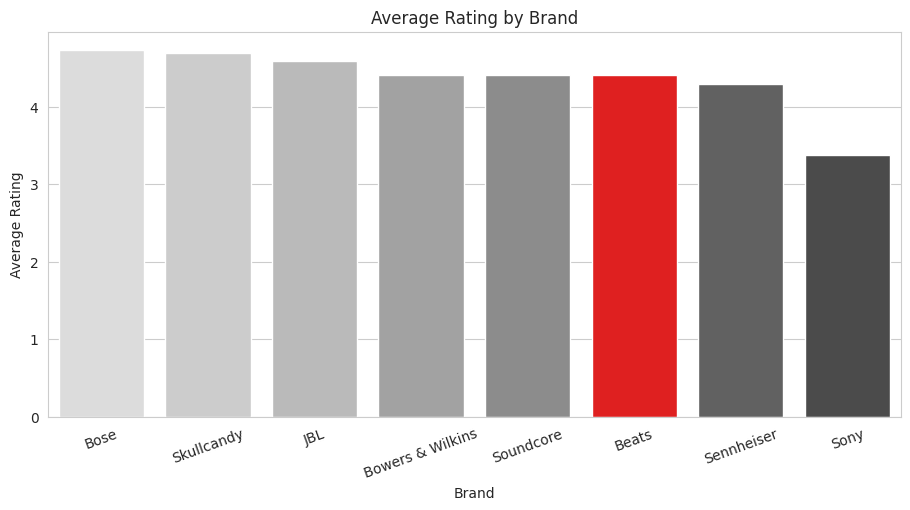

In [ ]:
plot_df=brand_summary.reset_index()
grays=sns.color_palette('Greys', len(plot_df)+4)[2:]

colors=['red' if 'beats' in brand.lower() else grays[i]
    for i, brand in enumerate(plot_df['brand_name'])]

plt.figure(figsize=(11,5))
sns.barplot(data=plot_df, x='brand_name', y='avg_rating', palette=colors)
plt.title('Average Rating by Brand')
plt.xlabel('Brand')
plt.ylabel('Average Rating')
plt.xticks(rotation=20)
plt.show()

In [ ]:
df['product_sum_name']= np.where(df['brand_name'].str.contains('beats', case=False, na=False), 'Beats' + df['beats_family'], df['product_name'])

In [ ]:
product_summary = (df.groupby(['brand_name', 'product_sum_name'])
      .agg(
          reviews=('rating', 'size'),
          avg_rating=('rating', 'mean'),
          percent_low_ratings=('rating', lambda x: x.isin([1, 2]).mean() * 100)
      )
      .reset_index()
      .sort_values('avg_rating', ascending=False)
)

In [ ]:
product_summary

,brand_name,product_sum_name,reviews,avg_rating,percent_low_ratings
7,Skullcandy,Skullcandy Crusher Evo Wireless Over-Ear Headp...,100,4.730000,0.000000
2,Bose,Bose QuietComfort Bluetooth Noise Cancelling H...,100,4.730000,0.000000
6,Skullcandy,Skullcandy Crusher ANC 2 Wireless Over-Ear Blu...,126,4.658730,0.000000
4,JBL,JBL Live 770NC Wireless Over-Ear Noise Cancell...,100,4.590000,2.000000
1,Beats,BeatsStudio Pro,199,4.512563,1.005025
9,Soundcore,Soundcore Space One Pro,100,4.410000,1.000000
3,Bowers & Wilkins,Bowers & Wilkins Px7 S3 Wireless Noise-Canceli...,100,4.410000,6.000000
0,Beats,BeatsSolo 4,300,4.336667,11.333333
5,Sennheiser,Sennheiser Momentum 4 Wireless Headphones,94,4.297872,2.127660
8,Sony,Sony WH-CH720N Noise Canceling Wireless Headph...,81,3.370370,35.802469


In [ ]:
plot_df=product_summary.sort_values('avg_rating', ascending=False).copy()

In [ ]:
colors = ['#ff1111' if 'beats' in name.lower() else '#bfbfbf'
    for name in plot_df['product_sum_name']]

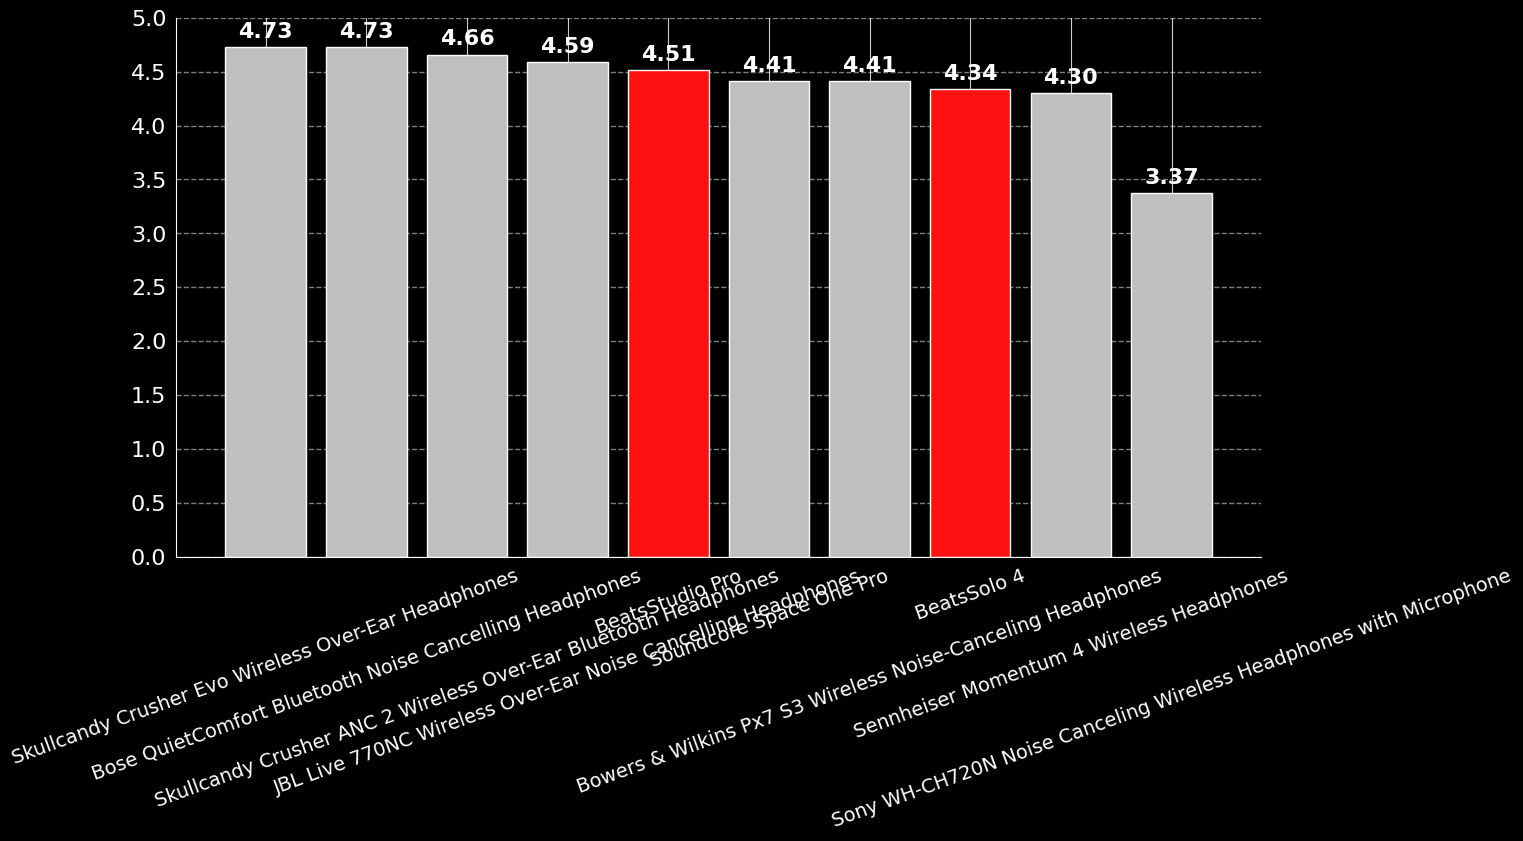

In [ ]:
fig, ax = plt.subplots(figsize=(14, 7), facecolor='black')
ax.set_facecolor('black')
bars = ax.bar(
    plot_df['product_sum_name'],
    plot_df['avg_rating'],
    color=colors,)
ax.set_ylim(0, 5)
ax.set_yticks(np.arange(0, 5.1, 0.5))
ax.grid(axis='y', linestyle='--', color='white', alpha=0.5, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(axis='x', colors='white', labelsize=14, rotation=20)
ax.tick_params(axis='y', colors='white', labelsize=16)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('white')

for bar, value in zip(bars, plot_df['avg_rating']):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.05,
        f'{value:.2f}',
        ha='center',
        va='bottom',
        color='white',
        fontsize=16,
        fontweight='bold')
plt.show()

In [ ]:
beats_df = df[df['brand_name'] == 'Beats']

family_summary = beats_df.groupby('beats_family').agg(
    reviews=('rating', 'size'),
    avg_rating=('rating', 'mean'),
    percent_low_ratings=('rating', lambda x: x.isin([1, 2]).mean() * 100)).reset_index().sort_values(['avg_rating', 'percent_low_ratings'], ascending=[True,False])

In [ ]:
family_summary

,beats_family,reviews,avg_rating,percent_low_ratings
0,Solo 4,300,4.336667,11.333333
1,Studio Pro,199,4.512563,1.005025


In [ ]:
asin_summary=(beats_df.groupby(['product_asin', 'product_name']).agg(
    reviews=('rating', 'size'),
    avg_rating=('rating', 'mean'),
    percent_low_ratings=('rating', lambda x: x.isin([1, 2]).mean() * 100)).reset_index().sort_values(['avg_rating', 'percent_low_ratings'], ascending=[True,False]))

In [ ]:
asin_summary

,product_asin,product_name,reviews,avg_rating,percent_low_ratings
4,B0FHLPS8ZF,Beats Solo 4 Wireless Bluetooth On-Ear Headphones,100,3.71000,28.0
1,B0CGKS9199,Beats Studio Pro Wireless Noise Cancelling Hea...,100,4.43000,2.0
2,B0D3KKP8GL,Beats Solo 4 Wireless On-Ear Headphones,100,4.54000,6.0
0,B0C8PR4W22,Beats Studio Pro Wireless Bluetooth Noise Canc...,99,4.59596,0.0
3,B0DB2YD3LD,Beats Solo 4 Wireless On-Ear Headphones,100,4.76000,0.0


/tmp/ipykernel_21722/1427227346.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.barplot(data=asin_summary, x='product_asin', y='avg_rating', palette='viridis')


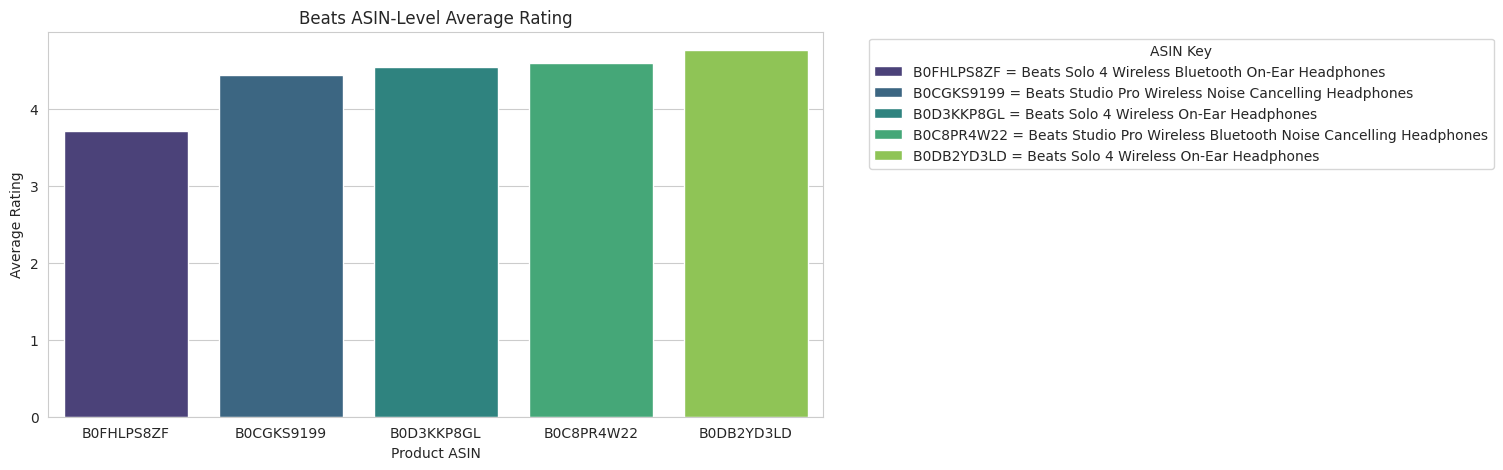

In [ ]:
plt.figure(figsize=(10, 5))
ax=sns.barplot(data=asin_summary, x='product_asin', y='avg_rating', palette='viridis')
plt.title('Beats ASIN-Level Average Rating')
plt.xlabel('Product ASIN')
plt.ylabel('Average Rating')
legend_items = [
    Patch(
        facecolor= ax.patches[i].get_facecolor(),
        label=f'{row.product_asin} = {row.product_name}')for i, row in enumerate(asin_summary.itertuples(index=False))]
plt.legend(
    handles=legend_items,
    title='ASIN Key',
    bbox_to_anchor=(1.05, 1),
    loc='upper left')
plt.show()

## Feature Performance Analysis

This section compares how often key product themes appear in reviews and how those themes relate to ratings for Beats versus competitors.

In [ ]:
rows=[]
for keyword in keyword_groups:
  count_col=f'{keyword}_count'
  beats_avg=df[(df['brand_group']=='Beats') & (df[count_col]>0)]['rating'].mean()
  beats_std=df[(df['brand_group']=='Beats') & (df[count_col]>0)]['rating'].std()
  comp_avg=df[(df['brand_group']=='Competitors') & (df[count_col]>0)]['rating'].mean()
  comp_std=df[(df['brand_group']=='Competitors') & (df[count_col]>0)]['rating'].std()
  rows.append([keyword, beats_avg, beats_std, comp_avg, comp_std])

In [ ]:
compare= pd.DataFrame(rows, columns=['keyword', 'beats_avg', 'beats_std', 'comp_avg', 'comp_std'])
compare['beats_vs'] = compare['beats_avg'] - compare['comp_avg']
compare['std_diff'] = compare['beats_std'] - compare['comp_std']
compare = compare.sort_values('beats_vs', ascending=False)
compare

,keyword,beats_avg,beats_std,comp_avg,comp_std,beats_vs,std_diff
3,quality,4.468354,0.857124,4.396947,0.963725,0.071408,-0.106601
5,noise_canceling,4.465116,0.797282,4.427451,0.861257,0.037665,-0.063975
0,sound,4.416667,0.890519,4.446018,0.868686,-0.029351,0.021832
4,connectivity,4.166667,1.150628,4.268817,1.057414,-0.102151,0.093213
2,comfort,4.401961,0.977568,4.508361,0.783061,-0.106400,0.194507
6,price_value,4.326087,1.139777,4.442568,0.907639,-0.116481,0.232138
1,battery,4.311111,1.147978,4.448980,0.869832,-0.137868,0.278146


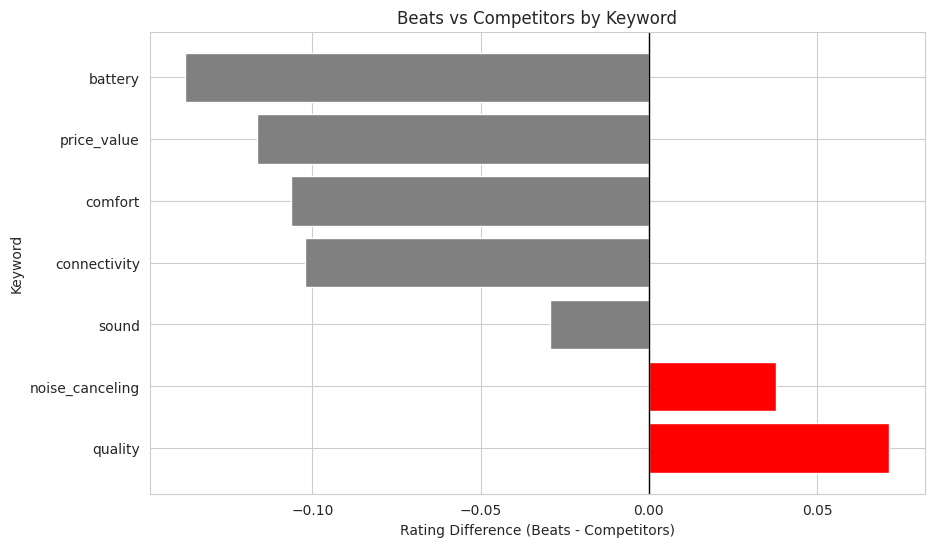

In [ ]:
colors = ['gray' if x < 0 else 'red' for x in compare['beats_vs']]

plt.figure(figsize=(10, 6))
plt.barh(compare['keyword'], compare['beats_vs'], color=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Beats vs Competitors by Keyword')
plt.xlabel('Rating Difference (Beats - Competitors)')
plt.ylabel('Keyword')
plt.show()

This comparison shows which feature themes are associated with stronger or weaker Beats performance relative to competitors.  
It helps separate broad brand perception from specific experience areas where Beats is outperforming or underperforming.

## Customer Sentiment Highlights

In [ ]:
theme_words = {
    'durability': ['broke', 'broken', 'stopped', 'working', 'months', 'year'],
    'charging': ['charge', 'charging', 'battery', 'power'],
    'connectivity': ['connect', 'pair', 'pairing', 'bluetooth', 'disconnect'],
    'comfort': ['hurt', 'pain', 'uncomfortable', 'comfort'],
    'sound': ['sound', 'audio', 'bass']
}

### Pain Points

In [ ]:
beats_negative= beats_df[beats_df['rating'].isin([1,2])].copy()

In [ ]:
for theme, words in theme_words.items():
  beats_negative[theme] = beats_negative['clean_review'].apply(lambda x: int(any(word in x for word in words)))

In [ ]:
negative_theme_summary=(beats_negative[list(theme_words.keys())].mean().mul(100).sort_values(ascending=False))

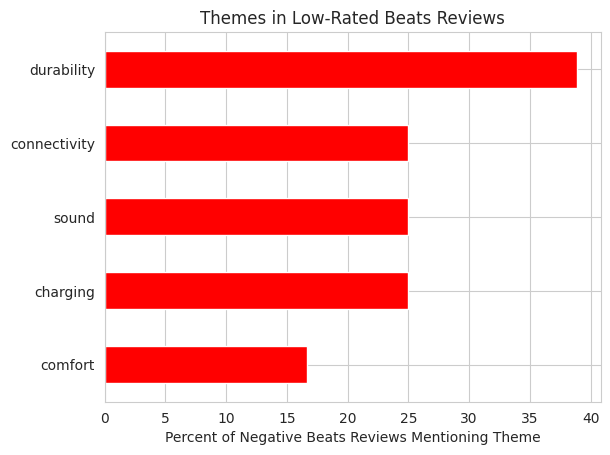

In [ ]:
negative_theme_summary.sort_values().plot(kind='barh', color='red')
plt.title('Themes in Low-Rated Beats Reviews')
plt.xlabel('Percent of Negative Beats Reviews Mentioning Theme')
plt.ylabel('')
plt.show()

## Major Pain Points in Negative Reviews

**1. Pain Point: Durability**  
Description: Durability complaints suggest that some customers are less frustrated by first-use performance and more frustrated by how quickly the headphones stop working. Several negative reviews mention one side failing, the headphones dying completely, or the product breaking down within months.  
Supporting Evidence: Durability-related language appears in 14 of 36 low-rated Beats reviews, or about 38.9%.  
Example Review: "9 months later, one side is no longer working. Only lightly used. Waste of money."

**2. Pain Point: Connectivity**  
Description: Connectivity complaints center on unreliable pairing and inconsistent device connection. These reviews suggest that even when customers like the sound, connection issues can seriously damage the overall experience.  
Supporting Evidence: Connectivity-related language appears in 9 of 36 low-rated Beats reviews, or 25.0%.  
Example Review: "It has a problem of connection and pairing with my phone. Connect and disconnect by itself"

**3. Pain Point: Charging and Battery**  
Description: Charging and battery complaints point to basic usability failure. In several low-rated reviews, customers describe the headphones as unable to charge, unable to power on, or effectively unusable after a short time.  
Supporting Evidence: Charging- and battery-related language appears in 10 of 36 low-rated Beats reviews, or 27.8%.  
Example Review: "I liked them while they worked but won’t charge now. Disappointed."

**4. Pain Point: Comfort**  
Description: Comfort complaints focus on physical discomfort during wear, especially around the ears during longer sessions. This matters because discomfort can reduce satisfaction even when sound quality is acceptable.  
Supporting Evidence: Comfort-related language appears in 6 of 36 low-rated Beats reviews, or 16.7%.  
Example Review: "They hurt your ears after 10-15 mins"

In [ ]:
beats_positive = beats_df[beats_df['rating'].isin([4, 5])].copy()
positive_theme_summary = (
    beats_positive[[f'{k}_flag' for k in keyword_groups.keys()]]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename(lambda x: x.replace('_flag', '')))

positive_theme_summary

,0
sound,43.981481
quality,33.333333
comfort,20.833333
price_value,18.287037
battery,17.129630
connectivity,13.425926
noise_canceling,9.259259


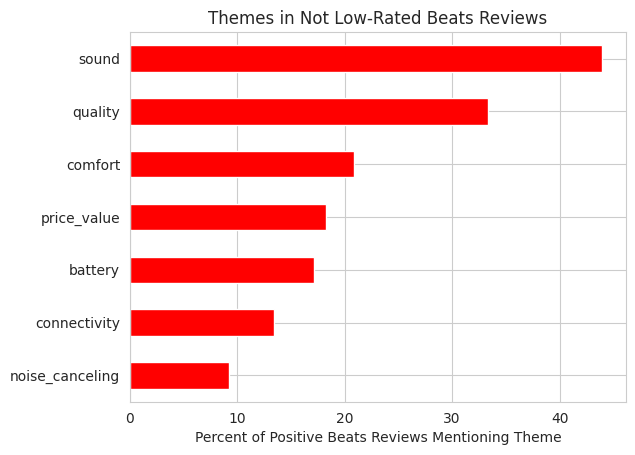

In [ ]:
positive_theme_summary.sort_values().plot(kind='barh', color='red')
plt.title('Themes in Not Low-Rated Beats Reviews')
plt.xlabel('Percent of Positive Beats Reviews Mentioning Theme')
plt.ylabel('')
plt.show()

## Top Four Strengths in Positive Reviews

**1. Strength: Sound**  
Description: Sound is the clearest strength in positive Beats reviews. Customers frequently describe the audio as clear, balanced, and enjoyable, with especially strong praise for bass, clarity, and overall listening experience.  
Supporting Evidence: Sound-related language appears in 202 of 432 positive Beats reviews, or about 46.8%.  
Example Review: "Sound is amazing!! Crisp, clear treble that isn't tinny, solid mid-range, and bass that vibrates my very soul."

**2. Strength: Quality**  
Description: Positive reviews often frame Beats as a solid overall product, with customers pointing to build quality, long-term satisfaction, and a premium feel. This suggests that many users see Beats as worth the purchase when the experience matches expectations.  
Supporting Evidence: Quality-related language appears in 145 of 432 positive Beats reviews, or 33.6%.  
Example Review: "Had for over two years with no issues. Great headphones and will get again if these ever break."

**3. Strength: Comfort**  
Description: Comfort is a recurring strength in positive reviews, especially when customers describe the headphones as easy to wear for everyday use. While comfort is also a pain point in some negative reviews, many satisfied customers still highlight it as a benefit.  
Supporting Evidence: Comfort-related language appears in 97 of 432 positive Beats reviews, or 22.5%.  
Example Review: "They are very comfortable too if you have a lot of earrings I got 9 and they did not bother me."

**4. Strength: Battery**  
Description: Battery performance is a meaningful positive theme, with customers often praising long battery life and convenient day-to-day use. This matters because battery reliability supports the product’s value as an everyday headphone.  
Supporting Evidence: Battery-related language appears in 86 of 432 positive Beats reviews, or 19.9%.  
Example Review: "The battery life is pretty long, and a full charge lasts all the way through an eight hour work shift."

## Brand Snapshots
Each brand snapshot shows overall performance, the most-mentioned themes, and example positive and negative reviews to support the written interpretation.

In [ ]:
def brand_snapshot(df, brand_name):
    brand_df = df[df['brand_name'] == brand_name].copy()

    summary = brand_df['rating'].agg(['count', 'mean']).rename({
        'count': 'reviews',
        'mean': 'avg_rating'
    })

    low_rating_pct = brand_df['rating'].isin([1, 2]).mean() * 100
    positive_pct = brand_df['rating'].isin([4, 5]).mean() * 100

    keyword_cols = [f'{k}_flag' for k in keyword_groups.keys()]
    keyword_summary = (
        brand_df[keyword_cols]
        .mean()
        .mul(100)
        .sort_values(ascending=False)
        .rename(lambda x: x.replace('_flag', ''))
    )

    positive_examples = brand_df[brand_df['rating'].isin([4, 5])][
        ['product_review_title', 'review_content']
    ].head(2)

    negative_examples = brand_df[brand_df['rating'].isin([1, 2])][
        ['product_review_title', 'review_content']
    ].head(2)

    print(f'Brand: {brand_name}')
    print(f"Reviews: {int(summary['reviews'])}")
    print(f"Average Rating: {summary['avg_rating']:.2f}")
    print(f"Positive Review %: {positive_pct:.1f}%")
    print(f"Low Rating %: {low_rating_pct:.1f}%")

    print('\nTop Mentioned Themes:')
    display(keyword_summary.head(5))

    print('\nPositive Example Reviews:')
    display(positive_examples)

    print('\nNegative Example Reviews:')
    display(negative_examples)

In [ ]:
brand_snapshot(df, 'Beats')

Brand: Beats
Reviews: 499
Average Rating: 4.41
Positive Review %: 86.6%
Low Rating %: 7.2%

Top Mentioned Themes:


,0
sound,43.286573
quality,31.663327
comfort,20.440882
price_value,18.436874
battery,18.036072



Positive Example Reviews:


,product_review_title,review_content
81,Fantastic,I am reviewing this item in brand new conditio...
82,"Great Sound, Good Quality.","Well, after having lost one of my AirPods (gen..."



Negative Example Reviews:


,product_review_title,review_content
185,Stopped turning on,No longer powers on .
190,Stopped working after 10 months,"Purchased these June 2025, do not use them dai..."


## Beats Snapshot

**Market Positioning:**
* Beats appears positioned as a premium lifestyle audio brand with strong design recognition and Apple ecosystem relevance.

**Key Strengths:**
* Beats performs competitively overall, with strong positive feedback around sound, design, and everyday usability.

**Main Challenges:**
* Dissatisfaction appears more concentrated in durability, charging, connectivity, comfort, and value concerns than in broad rejection of the brand.

**Target Audience Insight:**
* Beats seems to appeal most to buyers who care about brand image, recognizable design, and easy +everyday listening.



In [ ]:
brand_snapshot(df, 'Sony')

Brand: Sony
Reviews: 81
Average Rating: 3.37
Positive Review %: 53.1%
Low Rating %: 35.8%

Top Mentioned Themes:


,0
sound,45.679012
quality,35.802469
connectivity,29.629630
price_value,25.925926
comfort,20.987654



Positive Example Reviews:


,product_review_title,review_content
4,Amazing Headphones truly recommend.,For sure cancels all other noises allowing you...
5,Good for the $$,Would give them. 5 but they don't collapse.



Negative Example Reviews:


,product_review_title,review_content
0,Returned them immediately,Horrible. They don’t block out any noise. You ...
1,What's going on Sony,These feel very cheaply made. Ear cups are sma...


## Sony Snapshot

**Market Positioning:**
* Sony appears positioned as a technical-performance brand where customers expect strong features and reliable execution.

**Key Strengths:**
* Sony benefits from strong expectations around sound and technical capability when the experience meets those expectations.

**Main Challenges:**
* In this dataset, Sony performs more weakly than several other brands, which makes it especially important in the comparison.

**Target Audience Insight:**
* Sony seems to attract buyers who care about technical performance and expect strong connectivity, sound, and general functionality.

In [ ]:
brand_snapshot(df, 'Skullcandy')

Brand: Skullcandy
Reviews: 226
Average Rating: 4.69
Positive Review %: 92.9%
Low Rating %: 0.0%

Top Mentioned Themes:


,0
sound,62.831858
quality,40.707965
price_value,34.070796
connectivity,32.300885
battery,32.300885



Positive Example Reviews:


,product_review_title,review_content
480,Best headphones I've ever had,"First of all, a bit about me that's relevant. ..."
481,Personal favorites.,The Skullcandy Crusher Evo headphones stand ou...



Negative Example Reviews:


,product_review_title,review_content


## Skullcandy Snapshot

**Market Positioning:**
* Skullcandy appears positioned as a more bass-forward, value-oriented brand with strong mainstream appeal.

**Key Strengths:**
* It performs especially well in this dataset, suggesting strong satisfaction relative to price.

**Main Challenges:**
* Value brands can still be judged heavily on build quality and durability if customer expectations rise.

**Target Audience Insight:**
* Skullcandy seems to appeal to buyers who want strong bass, fun listening, and value.

In [ ]:
brand_snapshot(df, 'JBL')

Brand: JBL
Reviews: 100
Average Rating: 4.59
Positive Review %: 90.0%
Low Rating %: 2.0%

Top Mentioned Themes:


,0
sound,72.0
quality,51.0
price_value,44.0
battery,32.0
comfort,31.0



Positive Example Reviews:


,product_review_title,review_content
680,sub bass like Ive never experienced,"Made me say wow. jbl customer for life, becaus..."
681,Great find at sale price,Headphones and sound are a very subjective top...



Negative Example Reviews:


,product_review_title,review_content
721,unforgivably mid,"As someone who's bought numerous JBL products,..."
762,Audio control and sounds stopped working after...,These stopped working after 5 months. Let me e...


## JBL

**Market Positioning:**
* JBL appears positioned as a balanced mainstream brand offering familiar features and dependable overall performance.

**Key Strengths:**
* Its results suggest relatively steady satisfaction rather than one single standout strength.

**Main Challenges:**
* JBL may face differentiation pressure in a crowded market if it does not clearly dominate on sound, comfort, or value.

**Target Audience Insight:**
* JBL seems to appeal to buyers looking for a familiar brand and a lower-risk purchase decision.

In [ ]:
brand_snapshot(df, 'Sennheiser')

Brand: Sennheiser
Reviews: 94
Average Rating: 4.30
Positive Review %: 83.0%
Low Rating %: 2.1%

Top Mentioned Themes:


,0
sound,91.489362
quality,76.595745
comfort,64.893617
connectivity,57.446809
battery,53.191489



Positive Example Reviews:


,product_review_title,review_content
780,A casual review,Here's my opinion and rating after using these...
781,What you need to know...,"Before buying these, you gotta know some thing..."



Negative Example Reviews:


,product_review_title,review_content
784,Sent back in a week.,I had the most annoying week+ of trying to mak...
813,DO NOT BUY - HEADPHONES BRICK IF BATTERY DISCH...,UPDATE - BRICKS IF POWER DRAINS - DO NOT BUY!!...


## Sennheiser

**Market Positioning:**
* Sennheiser appears positioned as a more audio-credibility-driven brand with appeal tied to sound quality and brand reputation.

**Key Strengths:**
* Its differentiation likely comes more from perceived audio quality than from lifestyle branding.

**Main Challenges:**
* Its results are more mixed than some other competitors, which may suggest a gap between brand expectation and user experience.

**Target Audience Insight:**
* Sennheiser seems to attract buyers who care more about audio reputation and performance credibility.

In [ ]:
brand_snapshot(df, 'Soundcore')

Brand: Soundcore
Reviews: 100
Average Rating: 4.41
Positive Review %: 88.0%
Low Rating %: 1.0%

Top Mentioned Themes:


,0
sound,80.0
price_value,50.0
quality,50.0
noise_canceling,42.0
comfort,40.0



Positive Example Reviews:


,product_review_title,review_content
280,"Outstanding for home office use, 12+ hours of ...","I have been telecommuting for over 17 years, a..."
281,Baaaahaa!,Soundcore is the GOAT. The space one pro easil...



Negative Example Reviews:


,product_review_title,review_content
297,Space One Pro VS. Space One,My review is specifically comparing the Space ...


## Soundcore

**Market Positioning:**
* Soundcore appears positioned as a value-focused brand offering modern features at a more accessible price point.

**Key Strengths:**
* Its performance suggests that many customers see it as a strong practical alternative to more expensive brands.

**Main Challenges:**
* Lower-priced brands still need to maintain trust around reliability and long-term quality.

**Target Audience Insight:**
* Soundcore seems to appeal to price-conscious buyers who still want modern features and strong everyday usability.

In [ ]:
brand_snapshot(df, 'Bowers & Wilkins')

Brand: Bowers & Wilkins
Reviews: 100
Average Rating: 4.41
Positive Review %: 82.0%
Low Rating %: 6.0%

Top Mentioned Themes:


,0
sound,85.0
quality,50.0
comfort,39.0
noise_canceling,36.0
price_value,35.0



Positive Example Reviews:


,product_review_title,review_content
1074,"Knock your socks off sound, super comfy, high ...","I call myself an audiophile but honestly, just..."
1075,Oooh the sound quality!! 🎶🎶,These headphones are AMAZING!!!\n\nThe sound q...



Negative Example Reviews:


,product_review_title,review_content
1136,Quality lacking will not honor warranty,Do not buy if you want to be told that a 15ft ...
1140,Severe Connection Interference,Pro:\nFor the most part they sound beautiful a...


## Bowers & Wilkins

**Market Positioning:**
* Bowers & Wilkins appears positioned as a premium, design-forward brand with a more upscale identity.

**Key Strengths:**
* Its appeal likely comes from a combination of premium image, design, and higher-end expectations.

**Main Challenges:**
* Premium positioning raises expectations around comfort, value, and overall execution.

**Target Audience Insight:**
* Bowers & Wilkins seems to appeal to buyers who want a more luxury-oriented audio product.

In [ ]:
brand_snapshot(df, 'Bose')

Brand: Bose
Reviews: 100
Average Rating: 4.73
Positive Review %: 97.0%
Low Rating %: 0.0%

Top Mentioned Themes:


,0
sound,63.0
quality,49.0
comfort,45.0
connectivity,37.0
battery,33.0



Positive Example Reviews:


,product_review_title,review_content
380,Overall great headphones,These are my first headphones I’ve owned and I...
381,Bose Has Done it Again!,UPDATE 02/09/26: it’s been nearly 1 1/2 years ...



Negative Example Reviews:


,product_review_title,review_content


## Bose Snapshot

**Market Positioning:**
* Bose appears positioned as a premium comfort and noise-canceling brand with a strong reliability-oriented reputation.

**Key Strengths:**
* Bose performs very well in the dataset, supporting its image as a polished and dependable premium option.

**Main Challenges:**
* Premium brands are held to a higher standard, so even smaller disappointments in value or performance can have a stronger effect on customer reactions.

**Target Audience Insight:**
* Bose seems to appeal to customers who prioritize comfort, reliability, and a polished premium experience.

## Ecosystem Friction

This section checks whether Apple/iPhone and Samsung/Android language appears more often in negative reviews.

In [ ]:
ecosystem_negative=(df[df['rating'].isin([1,2])].groupby('brand_group')[[f'mentions_{t}' for t in ecosystem_terms]].mean().mul(100).round(2))

In [ ]:
ecosystem_negative

,mentions_android,mentions_samsung,mentions_iphone,mentions_apple
brand_group,,,,
Beats,0.0,2.78,5.56,5.56
Competitors,0.0,0.00,0.00,2.50


## Latest 12 Month Overview

In [ ]:
latest_date=df['date_of_review'].max()
recent_df = df[df['date_of_review'] >= latest_date - pd.DateOffset(months=12)].copy()

In [ ]:
recent_brand_summary = (recent_df.groupby('brand_name')
             .agg(
                 reviews=('rating', 'size'),
                 avg_rating=('rating', 'mean')
             )
             .sort_values('avg_rating', ascending=False))

In [ ]:
recent_brand_summary

,reviews,avg_rating
brand_name,,
Bose,93,4.731183
Skullcandy,191,4.722513
JBL,94,4.574468
Sennheiser,55,4.418182
Bowers & Wilkins,100,4.410000
Soundcore,89,4.404494
Beats,456,4.401316
Sony,81,3.370370


In [ ]:
price_summary = (df.groupby('brand_group').agg(
          reviews=('rating', 'size'),
          percent_price_mentions=('price_value_flag', lambda x: x.mean() * 100),
          avg_rating=('rating', 'mean')))

In [ ]:
bias_summary = (df.groupby('brand_group').agg(
          reviews=('rating', 'size'),
          percent_possible_bias=('possible_bias_flag', lambda x: x.mean() * 100),
          avg_bias_score=('possible_bias_score', 'mean')))

In [ ]:
price_summary

,reviews,percent_price_mentions,avg_rating
brand_group,,,
Beats,499,18.436874,4.406814
Competitors,801,36.953808,4.433208


In [ ]:
bias_summary

,reviews,percent_possible_bias,avg_bias_score
brand_group,,,
Beats,499,36.873747,3.286573
Competitors,801,65.543071,10.285893


In [ ]:
brand_summary

,reviews,avg_rating,percentage_of_low_ratings
brand_name,,,
Bose,100,4.730000,0.000000
Skullcandy,226,4.690265,0.000000
JBL,100,4.590000,2.000000
Bowers & Wilkins,100,4.410000,6.000000
Soundcore,100,4.410000,1.000000
Beats,499,4.406814,7.214429
Sennheiser,94,4.297872,2.127660
Sony,81,3.370370,35.802469


# Machine Learning

This section adds a machine learning layer to the analysis by using review text to predict low-rated reviews.  
The goal is not just to measure model performance, but to uncover which language patterns are most associated with dissatisfaction and where that risk appears most concentrated across Beats products.






In [ ]:
ml_df = df[['full_text', 'rating', 'brand_group', 'beats_family', 'product_asin', 'product_name']].copy()
ml_df['low_rating'] = ml_df['rating'].isin([1, 2]).astype(int)

In [ ]:
x = ml_df['full_text']
y = ml_df['low_rating']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
model = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        ngram_range=(1, 2),
        min_df=3,
        max_features=5000)),
    ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))])

In [ ]:
model.fit(x_train, y_train)

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=5000, min_df=3,
                                 ngram_range=(1, 2), stop_words='english')),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=2000))])

In [ ]:
y_pred = model.predict(x_test)
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.968     0.984     0.976       245
           1      0.636     0.467     0.538        15

    accuracy                          0.954       260
   macro avg      0.802     0.725     0.757       260
weighted avg      0.949     0.954     0.950       260



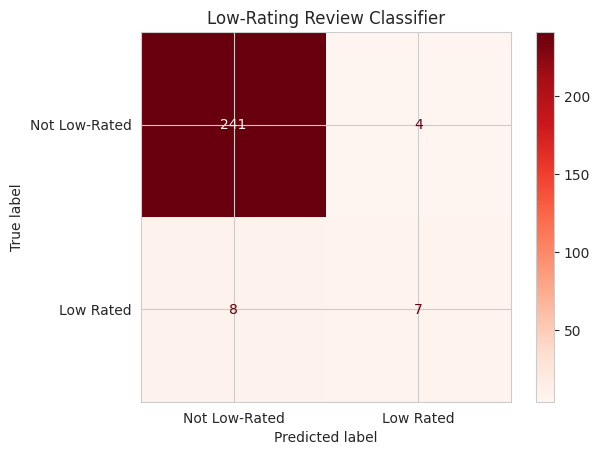

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=['Not Low-Rated', 'Low Rated'], cmap='Reds')
plt.title('Low-Rating Review Classifier')
plt.show()

In [ ]:
vectorizer = model.named_steps['tfidf']
clf = model.named_steps['clf']
feature_names = vectorizer.get_feature_names_out()
coefficients = clf.coef_[0]

In [ ]:
feature_importance = pd.DataFrame({'feature': feature_names, 'coefficient': coefficients})

In [ ]:
top_low_rating_features = feature_importance.sort_values('coefficient', ascending=False).head(15)
top_not_low_rating_features = feature_importance.sort_values('coefficient', ascending=True).head(15)

In [ ]:
print('Top features linked to low-rated reviews:')
display(top_low_rating_features)

Top features linked to low-rated reviews:


,feature,coefficient
2648,longer,2.432216
3218,pink,2.214512
2242,horrible,2.066003
3445,quality bass,1.807556
893,comfortable comfortable,1.753180
4619,warranty,1.717620
4802,year,1.660716
2863,months,1.482462
4625,waste money,1.409831
4110,stopped,1.366757


This model estimates whether a review is likely to be low-rated based only on its language.  
It helps test whether negative review text follows clear patterns that can be detected consistently.

In [ ]:
print('Top features linked to not-low-rated reviews:')
display(top_not_low_rating_features)

Top features linked to not-low-rated reviews:


,feature,coefficient
1866,great,-2.755206
2697,love,-2.065906
1802,good,-1.841492
3942,sound,-1.832955
1498,excellent,-1.343890
3166,perfect,-1.266128
206,amazing,-1.227177
4771,worth,-1.045724
2010,headphones,-1.004824
227,anc,-0.977379


These words and phrases are the strongest signals associated with low-rated or not-low-rated reviews.  
This helps show which topics are most connected to dissatisfaction versus satisfaction.

In [ ]:
ml_df['predicted_low_rating_risk'] = model.predict_proba(ml_df['full_text'])[:, 1]

In [ ]:
risk_by_group = (
    ml_df.groupby('brand_group')
    .agg(
        reviews=('low_rating', 'size'),
        actual_low_rating_pct=('low_rating', lambda x: x.mean() * 100),
        predicted_risk_pct=('predicted_low_rating_risk', lambda x: x.mean() * 100)).round(2))

In [ ]:
risk_by_group

,reviews,actual_low_rating_pct,predicted_risk_pct
brand_group,,,
Beats,499,7.21,23.30
Competitors,801,4.99,23.77


This compares actual low-rating rates with model-predicted complaint risk for Beats and competitors.  
It adds a text-based view of brand-level dissatisfaction beyond average star ratings alone.

In [ ]:
beats_risk_family = (
    ml_df[ml_df['brand_group'] == 'Beats']
    .groupby('beats_family')
    .agg(
        reviews=('low_rating', 'size'),
        actual_low_rating_pct=('low_rating', lambda x: x.mean() * 100),
        predicted_risk_pct=('predicted_low_rating_risk', lambda x: x.mean() * 100)).round(2).sort_values('predicted_risk_pct', ascending=False))

In [ ]:
beats_risk_family

,reviews,actual_low_rating_pct,predicted_risk_pct
beats_family,,,
Solo 4,300,11.33,25.17
Studio Pro,199,1.01,20.49


This compares Beats model families using both actual low ratings and predicted complaint risk.  
It helps identify whether one Beats family carries more dissatisfaction risk than another.

In [ ]:
beats_risk_by_asin = (
    ml_df[ml_df['brand_group'] == 'Beats'].groupby(['product_asin', 'product_name']).agg(
        reviews=('low_rating', 'size'),
        actual_low_rating_pct=('low_rating', lambda x: x.mean() * 100),
        predicted_risk_pct=('predicted_low_rating_risk', lambda x: x.mean() * 100)).round(2).reset_index().sort_values('predicted_risk_pct', ascending=False))

In [ ]:
beats_risk_by_asin

,product_asin,product_name,reviews,actual_low_rating_pct,predicted_risk_pct
4,B0FHLPS8ZF,Beats Solo 4 Wireless Bluetooth On-Ear Headphones,100,28.0,33.38
2,B0D3KKP8GL,Beats Solo 4 Wireless On-Ear Headphones,100,6.0,22.45
1,B0CGKS9199,Beats Studio Pro Wireless Noise Cancelling Hea...,100,2.0,21.33
3,B0DB2YD3LD,Beats Solo 4 Wireless On-Ear Headphones,100,0.0,19.68
0,B0C8PR4W22,Beats Studio Pro Wireless Bluetooth Noise Canc...,99,0.0,19.65


This compares individual Beats ASINs to see whether certain listings appear riskier than others.  
That can help separate product-level issues from listing-level or fulfillment-related issues.

##Classifier Conclusion

Overall, the analysis suggests that Beats remains competitive at the brand level, but the more meaningful variation appears at the model and ASIN level rather than in the aggregate. The review data shows that positive perception is most strongly tied to sound quality, overall product quality, comfort, and battery performance, while negative feedback is driven more by durability, charging, connectivity, and comfort-related concerns.

The machine learning results support this pattern by showing that low-rated reviews contain recognizable negative language signals and that complaint risk appears more concentrated in certain Beats families and listings than across the brand as a whole. While the model is best interpreted as a directional tool rather than a definitive measure, it strengthens the broader finding that Beats biggest opportunities appear to be targeted product and listing-level improvements rather than a broad brand perception problem.

## Regression Model

In [ ]:
rg_df = df[['full_text', 'rating', 'brand_group', 'beats_family', 'product_asin', 'product_name']].copy()
rg_df['normalized_rating'] = (rg_df['rating'] - 1) / 4
x = rg_df['full_text']
y = rg_df['normalized_rating']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

rg_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        ngram_range=(1, 2),
        min_df=3,
        max_features=5000)),
    ('ridge', Ridge(alpha=1.0))])
rg_model.fit(x_train, y_train)
y_pred = rg_model.predict(x_test)

In [ ]:
print('MAE:', round(mean_absolute_error(y_test, y_pred), 3))
print('R2_Score:', round(r2_score(y_test, y_pred), 3))

MAE: 0.147
R2_Score: 0.378


This model estimates how positive or negative review language is on a continuous scale rather than classifying reviews only as low-rated or not.  
That makes it useful for comparing whether some Beats models or ASINs seem to underperform relative to the tone of their review text.

In [ ]:
rg_df['predicted_rating'] = rg_model.predict(rg_df['full_text'])
rg_df['rating_gap']=rg_df['normalized_rating']-rg_df['predicted_rating']
rg_df[['rating', 'normalized_rating', 'predicted_rating', 'rating_gap']].head()

,rating,normalized_rating,predicted_rating,rating_gap
0,1,0.00,0.355913,-0.355913
1,2,0.25,0.457404,-0.207404
2,2,0.25,0.557162,-0.307162
3,2,0.25,0.586350,-0.336350
4,5,1.00,0.961908,0.038092


In [ ]:
beats_asin_rg=(rg_df[rg_df['brand_group'] == 'Beats'].groupby(['product_asin', 'product_name']).agg(
    reviews=('rating', 'size'),
    actual_norm_rating=('normalized_rating', 'mean'),
    predicted_norm_rating=('predicted_rating', 'mean'),
    average_rating_gap=('rating_gap', 'mean')).round(3).reset_index().sort_values('average_rating_gap'))

In [ ]:
beats_asin_rg

,product_asin,product_name,reviews,actual_norm_rating,predicted_norm_rating,average_rating_gap
4,B0FHLPS8ZF,Beats Solo 4 Wireless Bluetooth On-Ear Headphones,100,0.678,0.772,-0.094
1,B0CGKS9199,Beats Studio Pro Wireless Noise Cancelling Hea...,100,0.858,0.855,0.003
2,B0D3KKP8GL,Beats Solo 4 Wireless On-Ear Headphones,100,0.885,0.879,0.006
0,B0C8PR4W22,Beats Studio Pro Wireless Bluetooth Noise Canc...,99,0.899,0.879,0.020
3,B0DB2YD3LD,Beats Solo 4 Wireless On-Ear Headphones,100,0.940,0.902,0.038


This regression model predicts review sentiment on a continuous rating scale rather than only classifying reviews as low-rated or not. Its performance is moderate, which means it is best interpreted as a directional measure of review tone rather than a precise rating estimator. Even so, it adds value by showing whether some Beats products appear to perform above or below what their review language would suggest.

/tmp/ipykernel_21722/4134349693.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=beats_asin_rg, x='product_asin', y='average_rating_gap', palette='viridis')


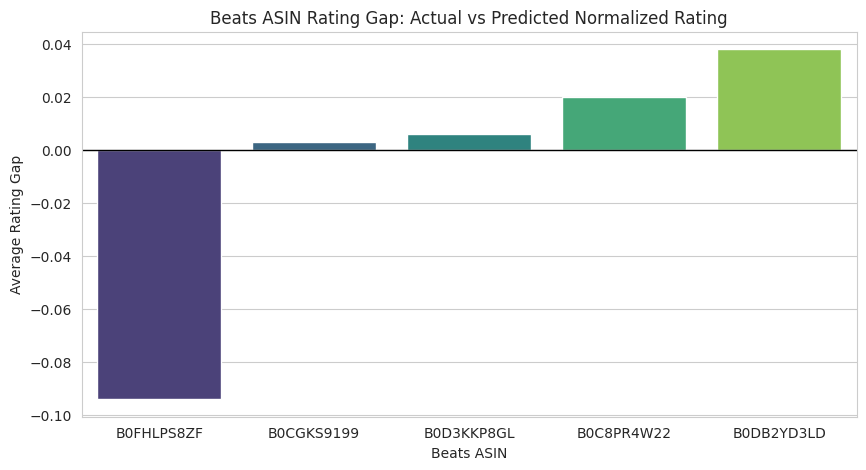

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=beats_asin_rg, x='product_asin', y='average_rating_gap', palette='viridis')
plt.axhline(0, color='black', linewidth=1)
plt.title('Beats ASIN Rating Gap: Actual vs Predicted Normalized Rating')
plt.xlabel('Beats ASIN')
plt.ylabel('Average Rating Gap')
plt.show()

This ASIN-level comparison helps show whether certain Beats listings underperform or overperform relative to the tone of their review language. A more negative rating gap suggests that actual ratings trail the overall tone of the written reviews, while a more positive gap suggests that ratings are stronger than the review text alone would predict.

## Strategic Recommendations

Recommendation: Reduce connectivity and charging friction in weaker Beats listings  
Current State: Low-rated Beats reviews frequently mention pairing, charging, and power-related issues, with complaint risk appearing more concentrated in specific ASINs than across the brand overall.  
Target State: Improve reliability in weaker listings and narrow the performance gap between underperforming and stronger Beats ASINs.  
Business Impact: Reducing these high-friction issues could improve customer satisfaction, strengthen trust in the product experience, and protect conversion on premium-priced models.

Recommendation: Improve comfort for extended wear  
Current State: Comfort-related complaints appear in low-rated reviews, particularly around ear pain and discomfort during longer listening sessions.  
Target State: Reduce comfort-related complaints and strengthen the product’s suitability for travel, work, and all-day use.  
Business Impact: Improving long-wear comfort could expand usage occasions, increase satisfaction, and make Beats more competitive in everyday premium headphone use cases.

Recommendation: Strengthen value perception through greater product consistency  
Current State: Some reviews suggest that performance, durability, or usability do not always feel fully aligned with the product’s premium price.  
Target State: Improve consistency across product experience and reinforce a stronger price-to-performance perception.  
Business Impact: Strengthening value perception could help Beats defend its premium positioning more effectively and reduce the risk of customers comparing it unfavorably to competing brands.

In [ ]:
summary_table = pd.DataFrame([
    ['Pain Point', 'Durability concerns', 'Durability-related language appears in 14 of 36 low-rated Beats reviews', '38.9% of negative Beats reviews'],
    ['Pain Point', 'Charging and battery problems', 'Charging- and battery-related language appears in 10 of 36 low-rated Beats reviews', '27.8% of negative Beats reviews'],
    ['Pain Point', 'Connectivity issues', 'Connectivity-related language appears in 9 of 36 low-rated Beats reviews', '25.0% of negative Beats reviews'],
    ['Pain Point', 'Comfort concerns', 'Comfort-related language appears in 6 of 36 low-rated Beats reviews', '16.7% of negative Beats reviews'],
    ['Strength', 'Strong sound perception', 'Sound-related language appears in 202 of 432 positive Beats reviews', '46.8% of positive Beats reviews'],
    ['Strength', 'Strong quality perception', 'Quality-related language appears in 145 of 432 positive Beats reviews', '33.6% of positive Beats reviews'],
    ['Strength', 'Comfort in positive use cases', 'Comfort-related language appears in 97 of 432 positive Beats reviews', '22.5% of positive Beats reviews'],
    ['Strength', 'Battery performance', 'Battery-related language appears in 86 of 432 positive Beats reviews', '19.9% of positive Beats reviews'],
    ['Recommendation', 'Reduce connectivity and charging friction in weaker ASINs', 'Complaint risk appears more concentrated in specific Beats listings than across the brand overall', 'High priority'],
    ['Recommendation', 'Improve comfort for extended wear', 'Ear pain and longer-wear discomfort appear in low-rated review themes', 'Medium priority'],
    ['Recommendation', 'Strengthen value perception through greater consistency', 'Some reviews suggest performance and durability do not always feel aligned with the premium price', 'High priority']
], columns=['Category', 'Finding', 'Supporting Evidence', 'Frequency/Impact'])

category_order = {
    'Pain Point': 0,
    'Strength': 1,
    'Recommendation': 2
}

summary_table['sort_order'] = summary_table['Category'].map(category_order)

summary_table = (
    summary_table
    .sort_values(['sort_order', 'Finding'])
    .drop(columns='sort_order')
    .reset_index(drop=True)
)

summary_table

,Category,Finding,Supporting Evidence,Frequency/Impact
0,Pain Point,Charging and battery problems,Charging- and battery-related language appears...,27.8% of negative Beats reviews
1,Pain Point,Comfort concerns,Comfort-related language appears in 6 of 36 lo...,16.7% of negative Beats reviews
2,Pain Point,Connectivity issues,Connectivity-related language appears in 9 of ...,25.0% of negative Beats reviews
3,Pain Point,Durability concerns,Durability-related language appears in 14 of 3...,38.9% of negative Beats reviews
4,Strength,Battery performance,Battery-related language appears in 86 of 432 ...,19.9% of positive Beats reviews
5,Strength,Comfort in positive use cases,Comfort-related language appears in 97 of 432 ...,22.5% of positive Beats reviews
6,Strength,Strong quality perception,Quality-related language appears in 145 of 432...,33.6% of positive Beats reviews
7,Strength,Strong sound perception,Sound-related language appears in 202 of 432 p...,46.8% of positive Beats reviews
8,Recommendation,Improve comfort for extended wear,Ear pain and longer-wear discomfort appear in ...,Medium priority
9,Recommendation,Reduce connectivity and charging friction in w...,Complaint risk appears more concentrated in sp...,High priority


## Conclusion

Overall, the analysis suggests that Beats remains competitive at the brand level, but the more meaningful variation appears at the model and ASIN level rather than in the aggregate. The review data shows that positive perception is most strongly tied to sound quality, overall product quality, comfort, and battery performance, while negative feedback is driven more by durability, charging, connectivity, and comfort-related concerns. This suggests that customer dissatisfaction is less about broad rejection of the brand and more about specific points of product friction.

The machine learning results reinforce this pattern by showing that low-rated reviews contain consistent negative language signals and that complaint risk appears more concentrated in certain Beats families and listings than across the brand as a whole. Taken together, these findings suggest that the strongest opportunity for Beats is not simply improving brand perception, but reducing targeted product and listing-level friction while strengthening consistency and value perception across the customer experience.